In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/Users/sreeharivenkataraman/Personal Files/DS_Projects/project_2/dataset/online_food_delivery_cleaned.csv")

In [3]:
df.isnull().sum()

Order_ID                   0
Customer_ID                0
Customer_Age               0
Customer_Gender            0
City                       0
Area                       0
Restaurant_ID              0
Restaurant_Name            0
Cuisine_Type               0
Order_Date              1014
Order_Time                 0
Delivery_Time_Min          0
Distance_km                0
Order_Value                0
Discount_Applied           0
Final_Amount               0
Payment_Mode               0
Order_Status               0
Cancellation_Reason        0
Delivery_Partner_ID        0
Delivery_Rating        15036
Restaurant_Rating          0
Order_Day                  0
Peak_Hour                  0
Profit_Margin              0
dtype: int64

In [4]:
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))

    return outliers

In [5]:
order_outliers = detect_outliers_iqr(
    df,
    "Order_Value"
)
order_outliers

Q1: 935.0
Q3: 2743.0
IQR: 1808.0
Lower Bound: -1777.0
Upper Bound: 5455.0
Number of Outliers: 0


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin


In [6]:
delivery_outliers = detect_outliers_iqr(
    df,
    "Delivery_Time_Min"
)
delivery_outliers

Q1: 58.0
Q3: 165.0
IQR: 107.0
Lower Bound: -102.5
Upper Bound: 325.5
Number of Outliers: 0


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin


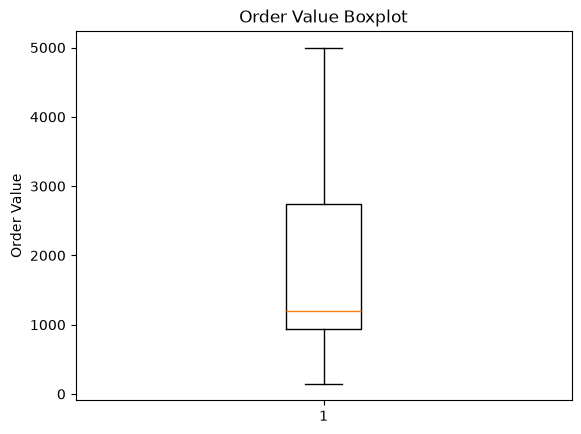

In [7]:
plt.boxplot(
    df["Order_Value"].dropna()
)

plt.title("Order Value Boxplot")
plt.ylabel("Order Value")

plt.show()

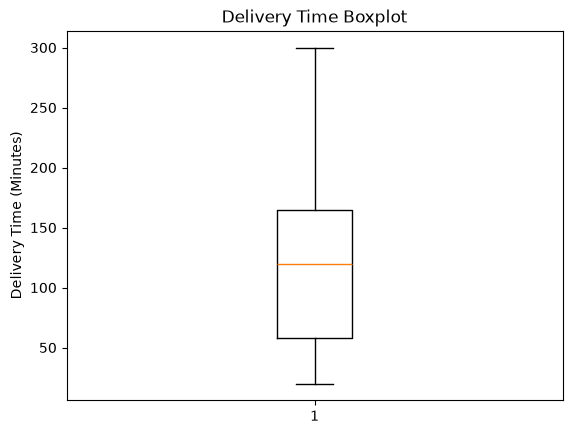

In [8]:
plt.boxplot(
    df["Delivery_Time_Min"].dropna()
)

plt.title("Delivery Time Boxplot")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

In [9]:
df["Order_Value"].dropna()

0        1197.0
1        4869.0
2         757.0
3        1197.0
4         372.0
          ...  
99995     232.0
99996    1098.0
99997    1197.0
99998    1197.0
99999    2909.0
Name: Order_Value, Length: 100000, dtype: float64

In [11]:
df["Order_Value"].isnull().sum()

np.int64(0)

In [12]:
df_clean = df.copy()

In [13]:
df_clean["Restaurant_Rating"] = (
    df_clean["Restaurant_Rating"].clip(upper=5)
)

In [14]:
df_clean["Restaurant_Rating"].min(), \
df_clean["Restaurant_Rating"].max()

(np.float64(3.0), np.float64(5.0))

In [15]:
(df_clean["Restaurant_Rating"] > 5).sum()

np.int64(0)

In [16]:
valid_profit_median = df_clean.loc[
    df_clean["Profit_Margin"] >= 0,
    "Profit_Margin"
].median()

valid_profit_median

np.float64(0.25)

In [17]:
df_clean.loc[
    df_clean["Profit_Margin"] < 0,
    "Profit_Margin"
] = valid_profit_median

In [18]:
(df_clean["Profit_Margin"] < 0).sum()

np.int64(0)

In [19]:
df_clean["Discount_Applied"] = np.minimum(
    df_clean["Discount_Applied"],
    df_clean["Order_Value"]
)

In [20]:
(
    df_clean["Discount_Applied"]
    > df_clean["Order_Value"]
).sum()

np.int64(0)

In [21]:
df_clean["Final_Amount"] = (
    df_clean["Order_Value"]
    - df_clean["Discount_Applied"]
)

In [22]:
(df_clean["Final_Amount"] < 0).sum()

np.int64(0)

In [23]:
df_clean["Final_Amount"].min()

np.float64(0.0)

In [24]:
df_clean.loc[
    df_clean["Order_Status"] == "Cancelled",
    "Delivery_Rating"
] = np.nan

In [25]:
df_clean.loc[
    df_clean["Order_Status"] == "Cancelled",
    "Delivery_Rating"
].notna().sum()

np.int64(0)

In [26]:
delivered_median_rating = df_clean.loc[
    df_clean["Order_Status"] == "Delivered",
    "Delivery_Rating"
].median()

df_clean.loc[
    (df_clean["Order_Status"] == "Delivered") &
    (df_clean["Delivery_Rating"].isna()),
    "Delivery_Rating"
] = delivered_median_rating

In [27]:
df_clean["Delivery_Rating"].isnull().sum()

np.int64(15036)

In [28]:
df_clean.loc[
    df_clean["Order_Status"] == "Delivered",
    "Cancellation_Reason"
] = "Not Applicable"

In [29]:
df_clean.loc[
    (df_clean["Order_Status"] == "Cancelled") &
    (df_clean["Cancellation_Reason"].isna()),
    "Cancellation_Reason"
] = "Unknown"

In [30]:
df_clean[
    ["Order_Status", "Cancellation_Reason"]
].value_counts()

Order_Status  Cancellation_Reason
Delivered     Not Applicable         84964
Cancelled     Unknown                 6005
              Late Delivery           3059
              Customer Cancelled      2993
              Restaurant Issue        2979
Name: count, dtype: int64

In [31]:
categorical_cols = [
    "Customer_Gender",
    "City",
    "Area",
    "Cuisine_Type",
    "Payment_Mode",
    "Order_Status",
    "Cancellation_Reason",
    "Order_Day"
]

for col in categorical_cols:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
    )

In [32]:
payment_mapping = {
    "UPI": "UPI",
    "COD": "COD",
    "Card": "Card",
    "Wallet": "Wallet",
    "Unknown": "Unknown"
}

df_clean["Payment_Mode"] = (
    df_clean["Payment_Mode"]
    .map(payment_mapping)
)

In [33]:
df_clean["Peak_Hour"] = df_clean["Peak_Hour"].replace({
    True: "Peak",
    False: "Non-Peak",
    "True": "Peak",
    "False": "Non-Peak"
})

df_clean["Peak_Hour"] = (
    df_clean["Peak_Hour"]
    .fillna("Unknown")
)

In [34]:
df_clean["Peak_Hour"].value_counts()

Peak_Hour
Non-Peak    33585
Peak        33453
Unknown     32962
Name: count, dtype: int64

In [35]:
df_clean["Order_Date"] = pd.to_datetime(
    df_clean["Order_Date"],
    errors="coerce"
)

In [36]:
expected_order_day = np.where(
    df_clean["Order_Date"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

In [37]:
mask = df_clean["Order_Date"].notna()

(
    df_clean.loc[mask, "Order_Day"]
    != expected_order_day[mask]
).sum()

0

In [38]:
df_clean["Profit_Margin_Percentage"] = (
    df_clean["Profit_Margin"] * 100
)

In [39]:
print("Restaurant rating > 5:",
      (df_clean["Restaurant_Rating"] > 5).sum())

print("Negative profit margin:",
      (df_clean["Profit_Margin"] < 0).sum())

print("Discount > order value:",
      (df_clean["Discount_Applied"] > df_clean["Order_Value"]).sum())

print("Negative final amount:",
      (df_clean["Final_Amount"] < 0).sum())

print(
    "Cancelled orders with delivery rating:",
    df_clean.loc[
        df_clean["Order_Status"] == "Cancelled",
        "Delivery_Rating"
    ].notna().sum()
)

Restaurant rating > 5: 0
Negative profit margin: 0
Discount > order value: 0
Negative final amount: 0
Cancelled orders with delivery rating: 0


In [40]:
df_clean.isnull().sum()[
    df_clean.isnull().sum() > 0
]

Order_Date          1014
Delivery_Rating    15036
dtype: int64

In [41]:
df_clean.to_csv(
    "online_food_delivery_preprocessed.csv",
    index=False
)